# PHASE 2: Exploratory Data Analysis (EDA)
### IndiaKart E-Commerce Data Analytics — Internmo Data Analyst Internship
**Analyst:** Kajal Rajak<br>
This project analyzes IndiaKart's e-commerce data to understand sales performance, customer behavior, product category performance, order patterns, payment preferences, and product returns.

In [12]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

indiakart_data = "indiakart_cleaned_data"

files = [f for f in os.listdir(indiakart_data) if f.endswith(".csv")]

loaded_files = {}

for file in sorted(files):
    table_name = file.replace(".csv", "")
    df = pd.read_csv(os.path.join(indiakart_data, file))
    loaded_files[table_name] = df

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
os.makedirs('EDA_charts', exist_ok=True)

## Chart 1.  Monthly order volume 

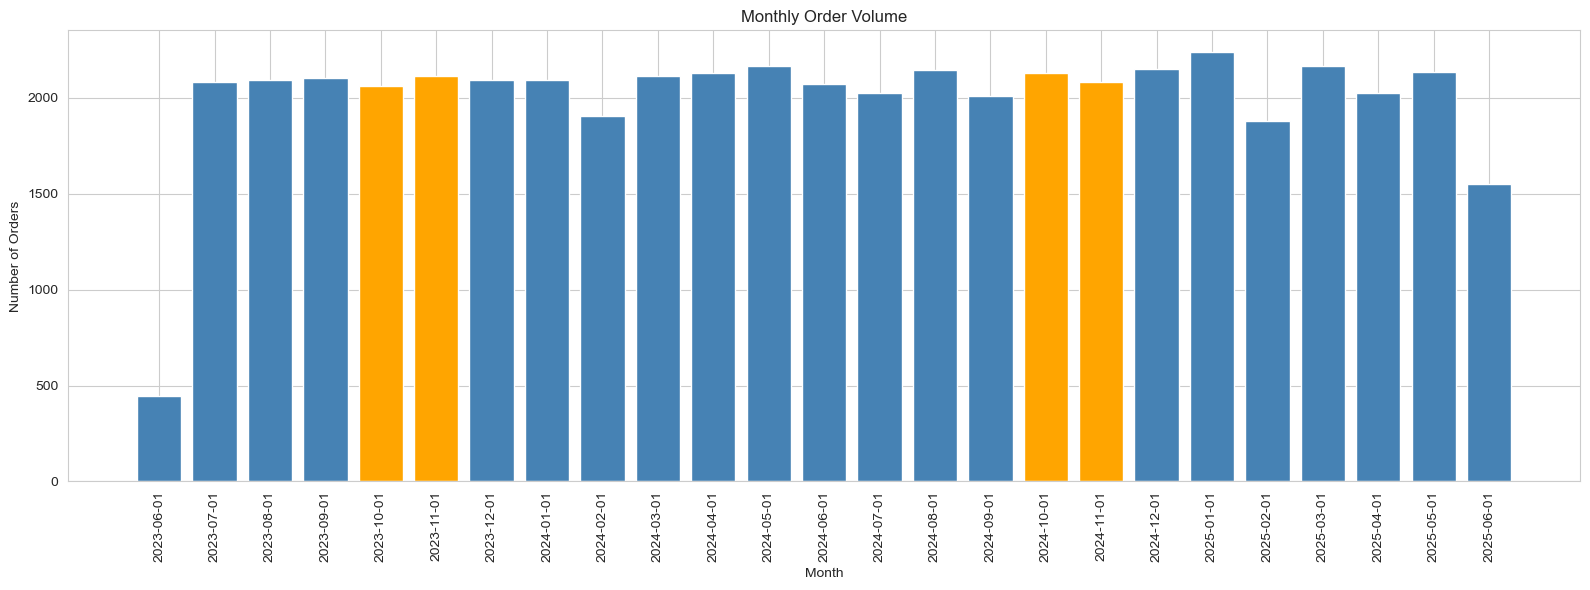

In [13]:
orders_df = loaded_files["orders DA"].copy()
orders_df["order_date_dt"] = pd.to_datetime(orders_df["order_date_dt"])

monthly_orders = (
    orders_df
    .set_index("order_date_dt")
    .resample("MS")["order_id"]
    .nunique()
    .reset_index()
)

monthly_orders.columns = ["month", "order_count"]
monthly_orders["month"] = monthly_orders["month"].astype(str)

bar_colors = ["orange" if month[5:7] in ("10", "11") else "steelblue" for month in monthly_orders["month"]]
plt.figure(figsize=(16, 6)) 
plt.bar(monthly_orders["month"], monthly_orders["order_count"], color=bar_colors) 

plt.title("Monthly Order Volume") 
plt.xlabel("Month") 
plt.ylabel("Number of Orders") 
plt.xticks(rotation=90) 
plt.tight_layout()
plt.savefig('EDA_charts/01_Monthly_order_volume.png')
plt.show()

**Observation:** Monthly order volume remained relatively stable from July 2023 to May 2025, with most months recording approximately 1,900–2,250 orders. The highlighted Diwali months (October and November) did not show a consistent increase in order volume compared with other months. June 2023 and June 2025 recorded fewer orders, likely because the dataset covers only part of each month.

## Chart 2. Monthly revenue (GMV) 

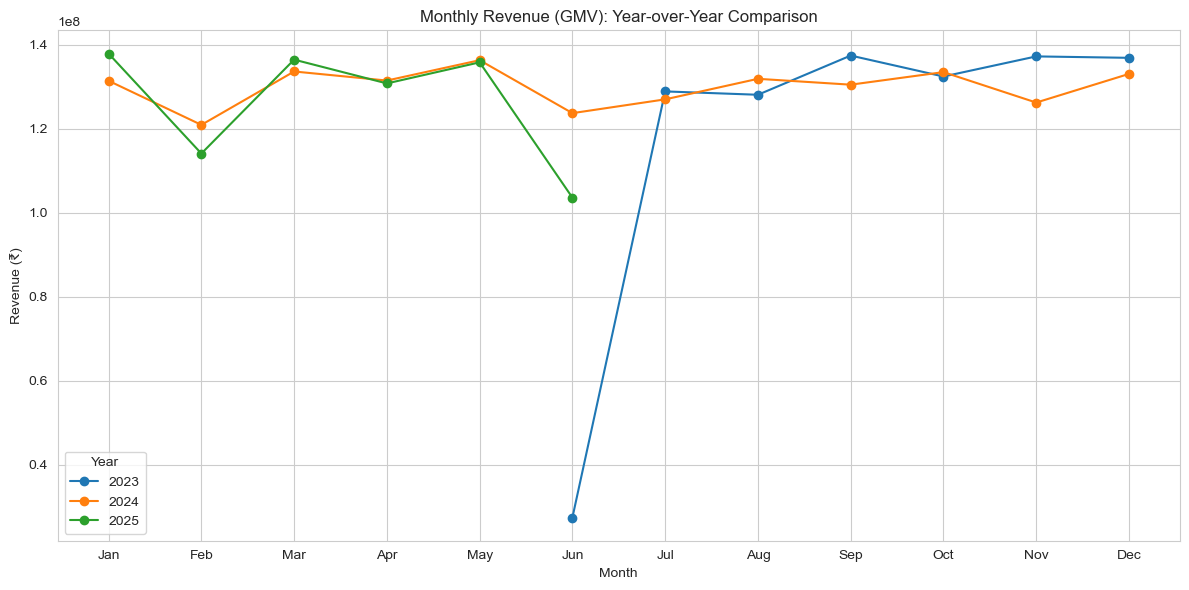

In [14]:
monthly_revenue = (
    orders_df
    .groupby([
        orders_df["order_date_dt"].dt.year.rename("year"),
        orders_df["order_date_dt"].dt.month.rename("month")
    ])["final_amount"]
    .sum()
    .reset_index()
)

monthly_revenue["month_name"] = pd.to_datetime(
    monthly_revenue["month"], format="%m"
).dt.strftime("%b")

revenue_comparison = monthly_revenue.pivot(
    index="month",
    columns="year",
    values="final_amount"
).reindex(range(1, 13))

revenue_comparison.index = pd.to_datetime(
    revenue_comparison.index, format="%m"
).strftime("%b")

plt.figure(figsize=(12, 6))

for year in revenue_comparison.columns:
    plt.plot(
        revenue_comparison.index,
        revenue_comparison[year],
        marker="o",
        label=str(year)
    )

plt.title("Monthly Revenue (GMV): Year-over-Year Comparison")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.legend(title="Year")
plt.tight_layout()
plt.savefig('EDA_charts/02_Monthly_revenue_(GMV).png')
plt.show()

**Observation:** Monthly revenue remained relatively stable across most months, with fluctuations between years. Revenue was generally higher in March–May than in February for both 2024 and 2025. June 2023 and June 2025 recorded lower revenue because these are partial months, while the year-over-year chart allows comparison of monthly revenue across the available years.

## Chart 3. Category-wise revenue share 

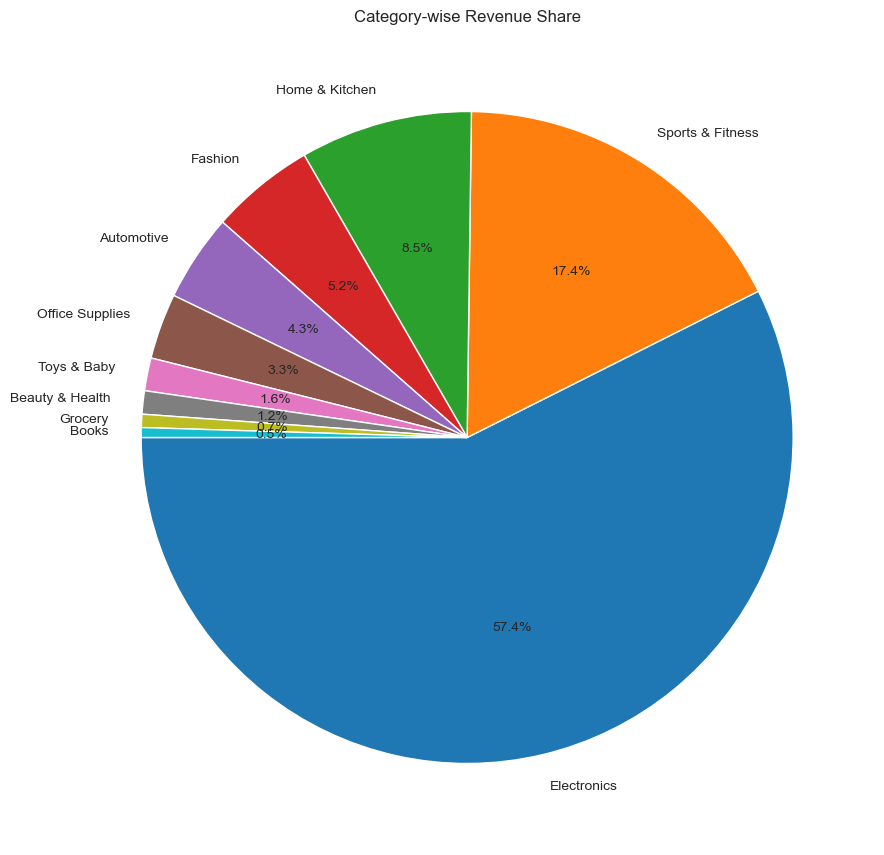

In [15]:
order_items_df = loaded_files["order_items DA_cleaned"].copy()

category_revenue = (
    order_items_df.groupby("category")["total_price"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

category_revenue.columns = ["category", "revenue"]

category_revenue["revenue_share"] = (
    category_revenue["revenue"] / category_revenue["revenue"].sum() * 100
)

plt.figure(figsize=(9, 9))

plt.pie(
    category_revenue["revenue_share"],
    labels=category_revenue["category"],
    autopct="%1.1f%%",
    startangle=180
)

plt.title("Category-wise Revenue Share")
plt.tight_layout()
plt.savefig('EDA_charts/03_Category-wise_revenue_share.png')
plt.show()

**Observation:** Electronics contributes the highest share of total revenue at 57.4%, followed by Sports & Fitness at 17.4% and Home & Kitchen at 8.5%. In contrast, Books (0.5%), Grocery (0.7%), and Beauty & Health (1.2%) contribute the smallest revenue shares. Overall, Electronics dominates category-wise revenue, accounting for more than half of the total.

## Chart 4. Order status distribution 

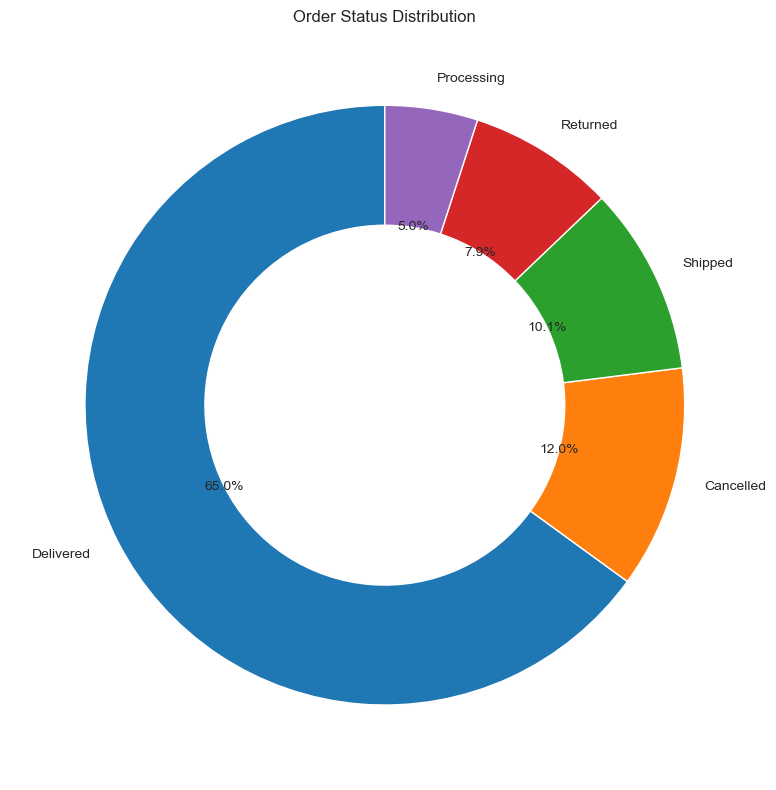

In [16]:
orders_df = loaded_files["orders DA"].copy()

status_counts = orders_df["status"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Order Status Distribution")
plt.tight_layout()
plt.savefig('EDA_charts/04_Order_status_distribution.png')
plt.show()

**Observation:** Delivered orders account for the largest share at 65%, indicating that most orders were successfully delivered. Cancelled orders represent 12%, followed by Shipped (10.1%), Returned (7.9%), and Processing (5%). Overall, the majority of orders were delivered, while cancellations and returns together account for 19.9% of orders.

## Chart 5. Top 10 states by number of orders 

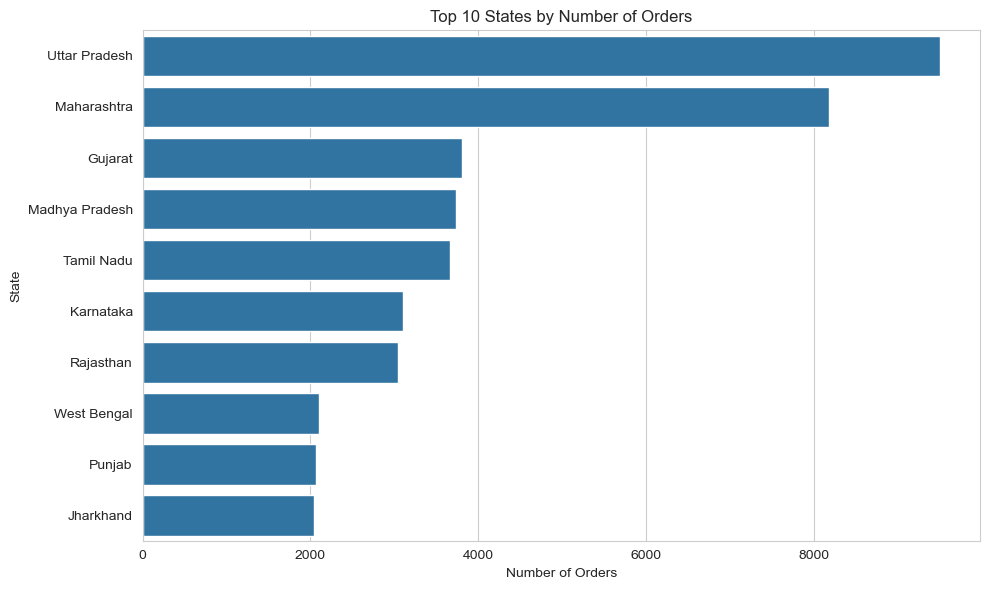

In [17]:
orders_df = loaded_files["orders DA"].copy()

top_states = (
    orders_df
    .groupby("state")["order_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_states.columns = ["state", "order_count"]

plt.figure(figsize=(10, 6))
sns.barplot(data=top_states, x="order_count", y="state")

plt.title("Top 10 States by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("State")
plt.tight_layout()
plt.savefig('EDA_charts/05_Top_10_states_by_number_of_orders.png')
plt.show()

**Observation:** Uttar Pradesh has the highest number of orders, followed by Maharashtra. Gujarat, Madhya Pradesh, and Tamil Nadu occupy the next positions. West Bengal, Punjab, and Jharkhand have comparatively fewer orders among the top 10 states. Overall, Uttar Pradesh and Maharashtra lead in order volume by a considerable margin.

## Chart 6. Customer segment distribution 

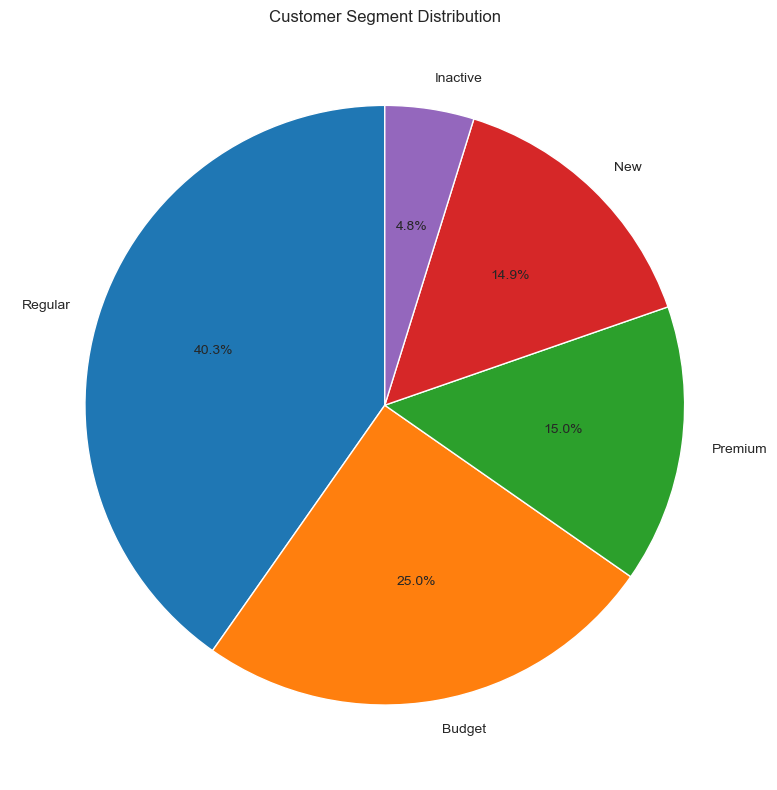

,customer_count
segment,
Regular,4026
Budget,2505
Premium,1501
New,1488
Inactive,480


In [18]:
customers_df = loaded_files["customers DA"].copy()

segment_counts = customers_df["segment"].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    segment_counts,
    labels=segment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Segment Distribution")
plt.tight_layout()
plt.savefig('EDA_charts/06_Customer_segment_distribution.png')
plt.show()
display(segment_counts.to_frame(name="customer_count"))

**Observation:** Regular customers form the largest segment, with 4,026 customers (40.3%), followed by Budget customers with 2,505 (25.1%) and Premium customers with 1,501 (15.0%). New customers account for 1,488 (14.9%), while Inactive customers represent the smallest segment, with 480 (4.8%). Overall, Regular customers make up the largest share of the customer base.

## Chart 7. Payment method usage

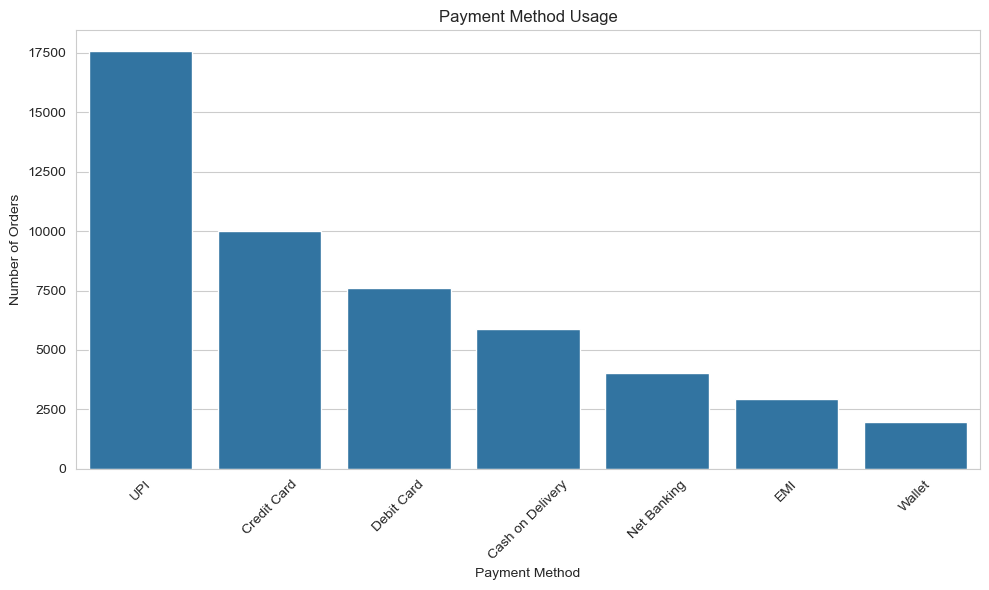

In [19]:
orders_df = loaded_files["orders DA"].copy()

payment_counts = (
    orders_df
    .groupby("payment_method")["order_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index()
)

payment_counts.columns = ["payment_method", "order_count"]

plt.figure(figsize=(10, 6))
sns.barplot(data=payment_counts, x="payment_method", y="order_count")

plt.title("Payment Method Usage")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('EDA_charts/07_Payment_method_usage.png')
plt.show()

**Observation:** UPI is the most widely used payment method, followed by Credit Card and Debit Card. Cash on Delivery and Net Banking show moderate usage, while EMI and Wallet are the least-used payment methods. Overall, UPI dominates customer payment preferences.

## Chart 8. Age distribution of customers 

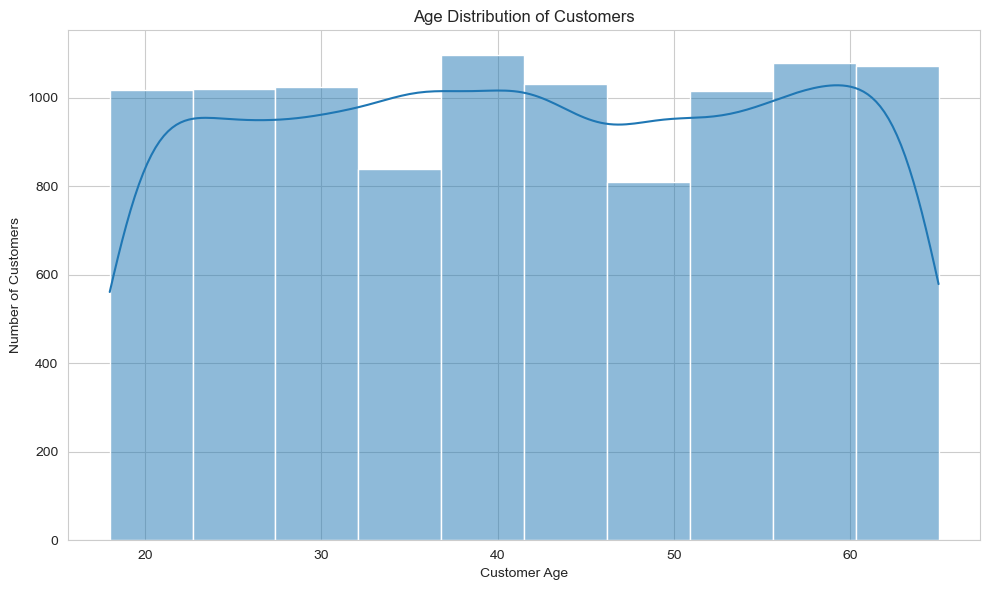

In [20]:
customers_df = loaded_files["customers DA"].copy()

plt.figure(figsize=(10, 6))

sns.histplot(
    data=customers_df,
    x="age",
    bins=10,
    kde=True
)

plt.title("Age Distribution of Customers")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig('EDA_charts/08_Age_distribution_of_customers.png')
plt.show()

**Observation:** Customer ages are distributed relatively evenly across the age range of approximately 18–65 years, with no single age group dominating the distribution. Slightly higher customer counts appear around ages 37–42 and 57–62, while the age groups around 33–37 and 47–52 show comparatively fewer customers. Overall, the customer base includes a broad range of adult age groups.


## Chart 9. Return reasons

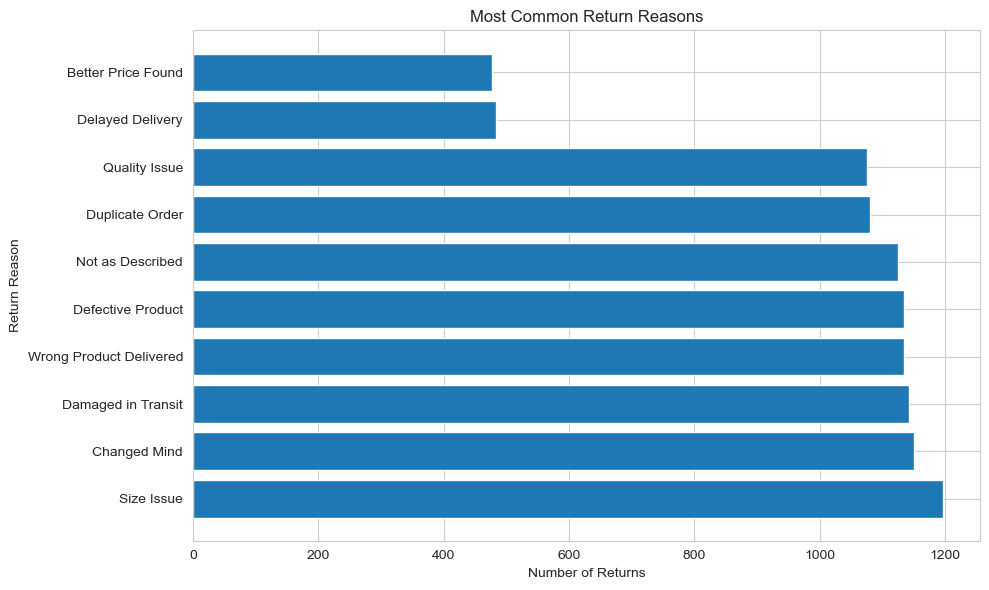

In [21]:
returns_df = loaded_files["returns DA"].copy()

return_reasons = (
    returns_df["reason"]
    .value_counts()
    .reset_index()
)

return_reasons.columns = ["reason", "return_count"]

plt.figure(figsize=(10, 6))
plt.barh(return_reasons["reason"], return_reasons["return_count"])

plt.title("Most Common Return Reasons")
plt.xlabel("Number of Returns")
plt.ylabel("Return Reason")
plt.tight_layout()
plt.savefig('EDA_charts/09_Return_reasons.png')
plt.show()

**Observation:** Size issues are the most common reason for returns, followed by changed minds and damaged products. Wrong products delivered, defective products, and items not as described also contribute significantly. Delayed delivery and finding a better price elsewhere are the least common reasons. Improving product quality, size guidance, and order accuracy could help IndiaKart reduce returns and associated costs.

## Chart 10. Average Order Value (AOV) by segment

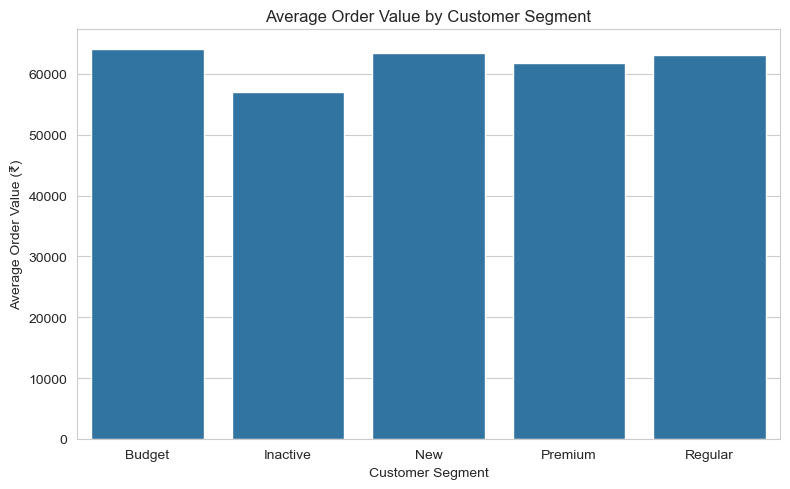

In [22]:
orders_df = loaded_files["orders DA_cleaned"].copy()
customers_df = loaded_files["customers DA_cleaned"].copy()

# Merge orders with customer segments
orders_segments = orders_df.merge(
    customers_df[["customer_id", "segment"]],
    on="customer_id",
    how="left"
)

# Calculate AOV by segment
aov_by_segment = (
    orders_segments
    .groupby("segment")["final_amount"]
    .mean()
    .reset_index()
)

aov_by_segment.columns = ["segment", "average_order_value"]

# Create bar chart
plt.figure(figsize=(8, 5))
sns.barplot(data=aov_by_segment, x="segment", y="average_order_value")

plt.title("Average Order Value by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Order Value (₹)")
plt.tight_layout()
plt.savefig('EDA_charts/10_Average_Order_Value_(AOV)_by_segment')
plt.show()

**Observation:** Budget customers have the highest average order value, followed by New and Regular customers. Premium customers rank fourth, while Inactive customers have the lowest average order value. Overall, **Premium customers do not spend the most per order; Budget customers have the highest AOV.**
